In [17]:
import json
import joblib
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import GroupShuffleSplit
import warnings
from lightgbm.basic import LGBMDeprecationWarning

warnings.filterwarnings(
    "ignore",
    category=LGBMDeprecationWarning
)

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, fbeta_score, average_precision_score
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier, early_stopping
from catboost import CatBoostClassifier

MODEL_DIR = Path("D:\\2026\\MedCare\\ML\\models")
MODEL_DIR.mkdir(exist_ok=True)

In [18]:
import pandas as pd

TRAIN_DIR = r"D:\2026\MedCare\ML\Dataset\Clean\Train"
TEST_DIR = r"D:\2026\MedCare\ML\Dataset\Clean\Test"

t2d_train = pd.read_csv(fr"{TRAIN_DIR}\t2d_train_engineered.csv")
t2d_test = pd.read_csv(fr"{TEST_DIR}\t2d_test_engineered.csv")

cvd_train = pd.read_csv(fr"{TRAIN_DIR}\cvd_train_engineered.csv")
cvd_test = pd.read_csv(fr"{TEST_DIR}\cvd_test_engineered.csv")

print("T2D:", t2d_train.shape, t2d_test.shape)
print("CVD:", cvd_train.shape, cvd_test.shape)

T2D: (35704, 41) (8928, 42)
CVD: (35704, 49) (8928, 50)


In [19]:
for name, train, test, target in [
    ("T2D", t2d_train, t2d_test, "T2D"),
    ("CVD", cvd_train, cvd_test, "CVD")
]:
    print(f"\n{name}")
    print("Train:", train[target].value_counts(normalize=True))
    print("Test :", test[target].value_counts(normalize=True))


T2D
Train: T2D
0.0    0.70754
1.0    0.29246
Name: proportion, dtype: float64
Test : T2D
0.0    0.702285
1.0    0.297715
Name: proportion, dtype: float64

CVD
Train: CVD
0.0    0.721628
1.0    0.278372
Name: proportion, dtype: float64
Test : CVD
0.0    0.731407
1.0    0.268593
Name: proportion, dtype: float64


In [20]:
def split_train_val(df, test_size=0.2):
    split = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=42)
    tr, val = next(split.split(df, groups=df["HHIDPN"]))
    return df.iloc[tr].copy(), df.iloc[val].copy()

t2d_train, t2d_val = split_train_val(t2d_train)
cvd_train, cvd_val = split_train_val(cvd_train)

print("T2D:", t2d_train.shape, t2d_val.shape, t2d_test.shape)
print("CVD:", cvd_train.shape, cvd_val.shape, cvd_test.shape)

T2D: (28560, 41) (7144, 41) (8928, 42)
CVD: (28560, 49) (7144, 49) (8928, 50)


In [21]:
def get_xy(train, val, test, target):
    drop = [target, "HHIDPN", "WAVE"]

    return (
        train.drop(columns=drop), train[target],
        val.drop(columns=drop), val[target],
        test.drop(columns=drop), test[target]
    )

X_t2d_train, y_t2d_train, X_t2d_val, y_t2d_val, X_t2d_test, y_t2d_test = \
    get_xy(t2d_train, t2d_val, t2d_test, "T2D")

X_cvd_train, y_cvd_train, X_cvd_val, y_cvd_val, X_cvd_test, y_cvd_test = \
    get_xy(cvd_train, cvd_val, cvd_test, "CVD")

In [22]:
def get_models(y_train, overrides=None):          # ← thêm overrides
    overrides = overrides or {}
    class_counts = y_train.value_counts()
    scale_pos_weight = np.sqrt(class_counts[0] / class_counts[1])

    return {
        "XGBoost": XGBClassifier(**{
            "n_estimators": 1000, "max_depth": 3, "learning_rate": 0.05,
            "subsample": 0.8, "colsample_bytree": 0.8,
            "reg_lambda": 15, "reg_alpha": 1, "random_state": 42,
            "eval_metric": ["logloss", "auc"], "early_stopping_rounds": 30,
            "scale_pos_weight": scale_pos_weight,
            **overrides.get("XGBoost", {})        # ← inject trial params
        }),

        "LightGBM": LGBMClassifier(**{
            "n_estimators": 1000, "max_depth": 3, "learning_rate": 0.05,
            "bagging_fraction": 0.8, "feature_fraction": 0.8, "bagging_freq": 1,
            "lambda_l2": 15, "random_state": 42, "verbosity": -1,
            "scale_pos_weight": scale_pos_weight,
            **overrides.get("LightGBM", {})
        }),

        "CatBoost": CatBoostClassifier(**{
            "iterations": 1000, "depth": 8, "learning_rate": 0.05,
            "subsample": 0.8, "l2_leaf_reg": 15, "random_seed": 42,
            "verbose": False, "eval_metric": "AUC",
            "auto_class_weights": "Balanced", "od_type": "Iter", "od_wait": 30,
            **overrides.get("CatBoost", {})
        }),
    }


In [23]:
# def get_models(y_train):
#     class_counts = y_train.value_counts()
#     scale_pos_weight = np.sqrt(class_counts[0] / class_counts[1])
#     # scale_pos_weight=1

#     return {
#         "XGBoost": XGBClassifier(
#             n_estimators=1000,
#             max_depth=3,
#             learning_rate=0.05,
#             subsample=0.8,
#             colsample_bytree=0.8,
#             reg_lambda=15, 
#             reg_alpha=1,
#             random_state=42,
#             eval_metric=["logloss", "auc"],
#             early_stopping_rounds=30,
#             scale_pos_weight=scale_pos_weight
#         ),

#         "LightGBM": LGBMClassifier(
#             n_estimators=1000,
#             max_depth=3,
#             learning_rate=0.05,
#             bagging_fraction=0.8,
#             feature_fraction=0.8,
#             bagging_freq=1, 
#             lambda_l2=15,
#             random_state=42,
#             verbosity=-1,
#             scale_pos_weight=scale_pos_weight
#         ),

#         "CatBoost": CatBoostClassifier(
#             iterations=1000,
#             depth=8,
#             learning_rate=0.05,
#             subsample=0.8, 
#             l2_leaf_reg=15, 
#             random_seed=42,
#             verbose=False,
#             eval_metric="AUC",
#             auto_class_weights="Balanced",
#             od_type="Iter",
#             od_wait=30
#         )
#     }

In [24]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def fit_one(name, model, X_tr, y_tr, X_vl, y_vl):
    """Fit 1 model — rút từ train_models()."""
    if name == "LightGBM":
        model.fit(X_tr, y_tr, eval_set=[(X_vl, y_vl)], eval_names=["val"],
                  callbacks=[early_stopping(30, verbose=False)])
    else:
        model.fit(X_tr, y_tr, eval_set=[(X_vl, y_vl)], verbose=False)
    return model


SEARCH_SPACE = {
    "XGBoost":  {"max_depth": ("int", 2, 6),
                 "learning_rate": ("float", 0.01, 0.1),
                 "subsample": ("float", 0.6, 1.0),
                 "colsample_bytree": ("float", 0.6, 1.0),
                 "reg_lambda": ("float", 1, 20),
                 "reg_alpha": ("float", 0, 5)},
    "LightGBM": {"max_depth": ("int", 2, 6),
                 "learning_rate": ("float", 0.01, 0.1),
                 "bagging_fraction": ("float", 0.6, 1.0),
                 "feature_fraction": ("float", 0.6, 1.0),
                 "lambda_l2": ("float", 1, 20)},
    "CatBoost": {"depth": ("int", 4, 10),
                 "learning_rate": ("float", 0.01, 0.1),
                 "l2_leaf_reg": ("float", 1, 20),
                 "subsample": ("float", 0.6, 1.0)},
}

N_TRIALS = 50
best_params = {}

for disease, X_tr, y_tr, X_vl, y_vl in [
    ("T2D", X_t2d_train, y_t2d_train, X_t2d_val, y_t2d_val),
    ("CVD", X_cvd_train, y_cvd_train, X_cvd_val, y_cvd_val),
]:
    best_params[disease] = {}
    print(f"\n{'='*50}\n{disease}\n{'='*50}")

    for model_name, space in SEARCH_SPACE.items():

        def objective(trial, name=model_name, space=space):
            params = {
                k: trial.suggest_int(k, *v[1:]) if v[0] == "int"
                   else trial.suggest_float(k, *v[1:], log=(k == "learning_rate"))
                for k, v in space.items()
            }
            model = get_models(y_tr, {name: params})[name]   
            fit_one(name, model, X_tr, y_tr, X_vl, y_vl)    
            return average_precision_score(y_vl, model.predict_proba(X_vl)[:, 1])

        study = optuna.create_study(direction="maximize")
        study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)

        best_params[disease][model_name] = study.best_params
        print(f"{model_name:10s}  PR-AUC={study.best_value:.4f}  {study.best_params}")

with open(MODEL_DIR / "optuna_best_params.json", "w") as f:
    json.dump(best_params, f, indent=2)
print("\nSaved: optuna_best_params.json")



T2D


d:\2026\MedCare\ML\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Best trial: 18. Best value: 0.533215: 100%|██████████| 50/50 [00:47<00:00,  1.05it/s]


XGBoost     PR-AUC=0.5332  {'max_depth': 2, 'learning_rate': 0.024231013177265816, 'subsample': 0.6614321631523238, 'colsample_bytree': 0.7842100042641769, 'reg_lambda': 14.25557555119765, 'reg_alpha': 0.6788985387061071}


Best trial: 31. Best value: 0.533039: 100%|██████████| 50/50 [00:17<00:00,  2.91it/s]


LightGBM    PR-AUC=0.5330  {'max_depth': 3, 'learning_rate': 0.054171905770298075, 'bagging_fraction': 0.6292551729274963, 'feature_fraction': 0.8202802941413079, 'lambda_l2': 17.40126928235265}


Best trial: 19. Best value: 0.533098: 100%|██████████| 50/50 [00:57<00:00,  1.15s/it]


... (3 outputs left out)

Best trial: 42. Best value: 0.551857: 100%|██████████| 50/50 [00:37<00:00,  1.33it/s]


LightGBM    PR-AUC=0.5519  {'max_depth': 2, 'learning_rate': 0.03371534101754638, 'bagging_fraction': 0.8470981761695405, 'feature_fraction': 0.8542824653492848, 'lambda_l2': 11.683378002147442}


Best trial: 45. Best value: 0.548855: 100%|██████████| 50/50 [03:18<00:00,  3.97s/it]

CatBoost    PR-AUC=0.5489  {'depth': 4, 'learning_rate': 0.05755321977908666, 'l2_leaf_reg': 7.575090589305957, 'subsample': 0.6457679854946904}

Saved: optuna_best_params.json


In [25]:
def train_models(X_train, y_train, X_val, y_val, disease, overrides=None):
    models = get_models(y_train, overrides)
    histories = {}

    for name, model in models.items():

        if name == "XGBoost":
            model.fit(
                X_train, y_train,
                eval_set=[(X_train, y_train), (X_val, y_val)],
                verbose=False
            )
            histories[name] = model.evals_result()

        elif name == "LightGBM":
            model.fit(
                X_train, y_train,
                eval_set=[(X_train, y_train), (X_val, y_val)],
                eval_names=["train", "val"],
                callbacks=[early_stopping(30, verbose=False)]
            )
            histories[name] = model.evals_result_

        else:
            model.fit(
                X_train, y_train,
                eval_set=[(X_train, y_train), (X_val, y_val)],
                verbose=False
            )
            histories[name] = model.get_evals_result()

        best_iteration = getattr(model, "best_iteration_", None)
        if best_iteration is None:
            best_iteration = getattr(model, "best_iteration", None)

        print(f"{disease} - {name}: best iteration = {best_iteration}")

        joblib.dump(
            model,
            MODEL_DIR / f"{disease}_{name.lower()}.pkl"
        )

    with open(MODEL_DIR / f"{disease}_history.json", "w") as f:
        json.dump(histories, f, indent=2)

    return models, histories

In [26]:
with open(MODEL_DIR / "optuna_best_params.json") as f:
    best_params = json.load(f)

t2d_models, t2d_history = train_models(
    X_t2d_train,
    y_t2d_train,
    X_t2d_val,
    y_t2d_val,
    "t2d",
    overrides=best_params["T2D"]
)

t2d - XGBoost: best iteration = 176
t2d - LightGBM: best iteration = 138
t2d - CatBoost: best iteration = 25


In [27]:
cvd_models, cvd_history = train_models(
    X_cvd_train,
    y_cvd_train,
    X_cvd_val,
    y_cvd_val,
    "cvd",
    overrides=best_params["CVD"]
)

cvd - XGBoost: best iteration = 433
cvd - LightGBM: best iteration = 422
cvd - CatBoost: best iteration = 197


In [28]:
def plot_loss(histories, disease):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for ax, (name, h) in zip(axes, histories.items()):

        if name == "XGBoost":
            train = h["validation_0"]["logloss"]
            val = h["validation_1"]["logloss"]

        elif name == "LightGBM":
            train = h["train"]["binary_logloss"]
            val = h["val"]["binary_logloss"]

        else:  # CatBoost
            train = h["learn"]["Logloss"]
            val_key = [k for k in h if k != "learn"][0]
            val = h[val_key]["Logloss"]

        ax.plot(train, label="Train Loss")
        ax.plot(val, label="Validation Loss")

        ax.set_title(name)
        ax.set_xlabel("Iteration")
        ax.set_ylabel("Log Loss")
        ax.legend()
        ax.grid(alpha=0.3)

    fig.suptitle(f"{disease} - Loss Curve", fontsize=14)
    plt.tight_layout()
    plt.show()

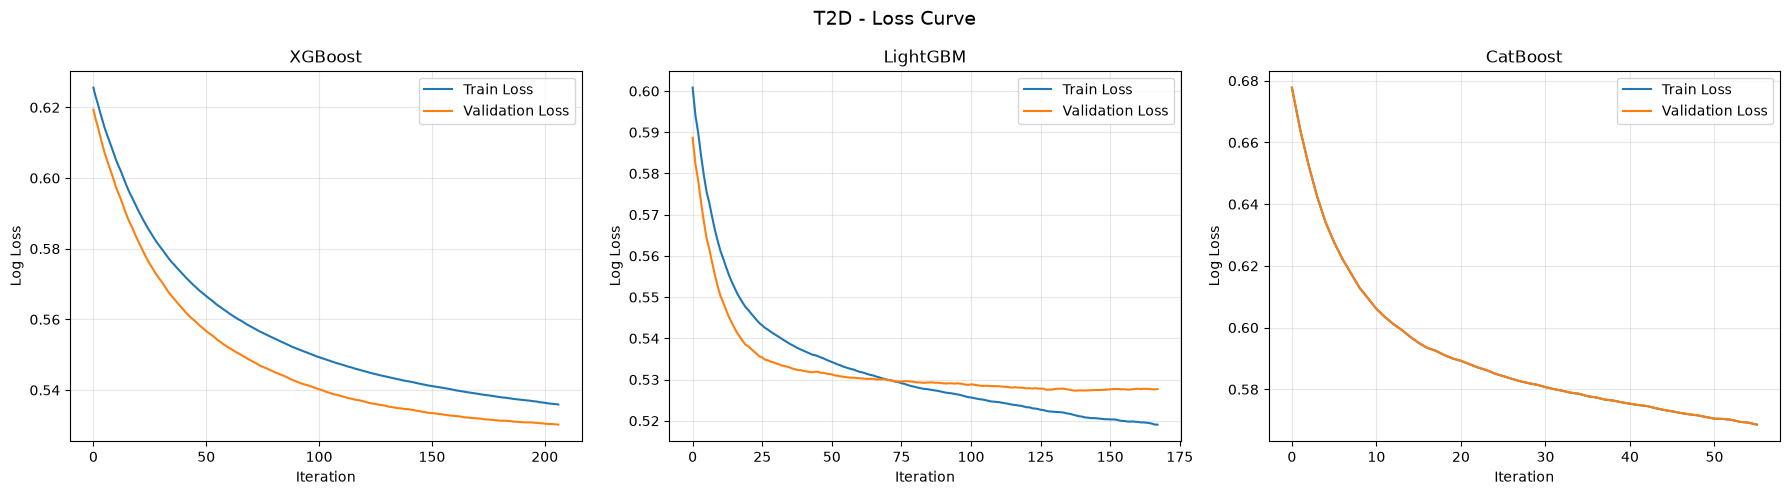

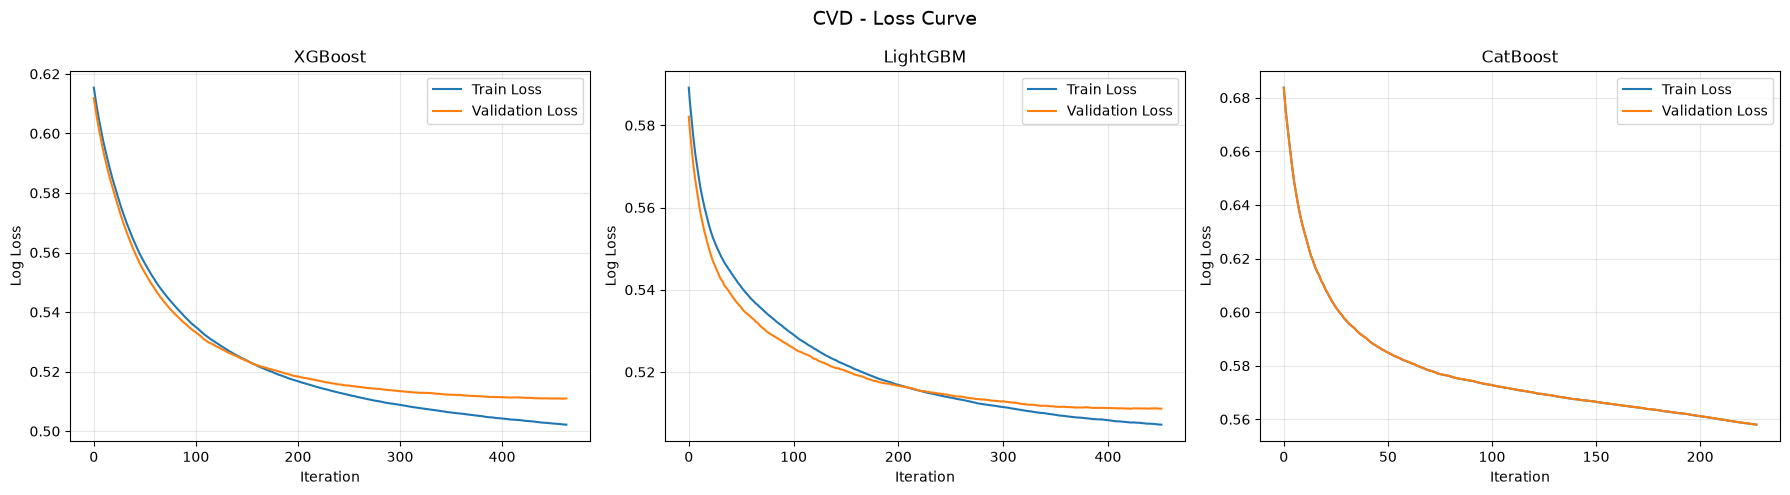

In [29]:
plot_loss(t2d_history, "T2D")
plot_loss(cvd_history, "CVD")

In [30]:
h = t2d_history["CatBoost"]

val_key = [k for k in h if k != "learn"][0]

print("Train:", h["learn"]["Logloss"][:])
print("Val:  ", h[val_key]["Logloss"][:])

Train: [0.6777570754043504, 0.6639379055279033, 0.6524291018448163, 0.6423417391121017, 0.6340378312084907, 0.6276287007679382, 0.6221684389936802, 0.617569763093741, 0.6129157443054112, 0.6095242918311993, 0.6060880470691069, 0.6034301903732281, 0.6011787395337376, 0.5992307481048404, 0.5970188218346082, 0.5950446191840353, 0.5934484640497036, 0.5925091452083606, 0.5911316686315429, 0.5900026148749019, 0.5892229136698494, 0.5881619824022171, 0.5870715949739765, 0.5862421825175403, 0.5851063416830201, 0.5842811294512769, 0.5834094963968804, 0.582613136827757, 0.581991088099716, 0.5814618688863683, 0.5807215315199539, 0.5800661327045858, 0.579528552466344, 0.5788927658192714, 0.5785372903408564, 0.5777469172291652, 0.5773571424429691, 0.5766882604514388, 0.5763558725618955, 0.5757966604083218, 0.5753233966793126, 0.574893584805466, 0.5745801540311252, 0.5739107443579368, 0.573311573965696, 0.5728508350944355, 0.5723293430814614, 0.571894427252266, 0.5715596132401564, 0.5710223878223398,

In [31]:
def evaluate_models(models, X, y, dataset, threshold=0.5):
    results = []

    for name, model in models.items():
        prob = model.predict_proba(X)[:, 1]
        pred = (prob >= threshold).astype(int)

        results.append({
            "Model": name,
            "Dataset": dataset,
            "Threshold": threshold,
            "Accuracy": accuracy_score(y, pred),
            "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0),
            "F1": f1_score(y, pred, zero_division=0),
            "F2": fbeta_score(y, pred, beta=2, zero_division=0),
            "ROC_AUC": roc_auc_score(y, prob),
            "PR_AUC": average_precision_score(y, prob)
        })

    return results

In [32]:
t2d_results = (
    evaluate_models(t2d_models, X_t2d_val, y_t2d_val, "Validation")
    + evaluate_models(t2d_models, X_t2d_test, y_t2d_test, "Test")
)

print(pd.DataFrame(t2d_results))

ValueError: feature_names mismatch: ['RAGENDER', 'AGEY_B', 'HEIGHT', 'WEIGHT', 'PMBMI', 'PMWAIST', 'SMOKEV', 'SMOKEN', 'VGACTX', 'MDACTX', 'LTACTX', 'DRINK', 'DRINKD', 'DRINKN', 'SLEEP', 'SLEEPE', 'SLEEPFAL', 'SLEEPSN', 'SLEEPBR', 'HIBP', 'HIBPS', 'HIBPE', 'ARTHR', 'ARTHRE', 'ARTHRS', 'DRUGS', 'BPMED', 'HIGHCHOL', 'CHOLMED', 'MENOPAUSE', 'ITOT', 'FE_WtHR', 'FE_BMI_Waist', 'FE_Weekly_Drinks', 'FE_Smoking_Status', 'FE_Physical_Activity_Score', 'FE_Sleep_Disturbance_Index', 'FE_Log_Income'] ['RAGENDER', 'AGEY_B', 'HEIGHT', 'WEIGHT', 'PMBMI', 'PMWAIST', 'SMOKEV', 'SMOKEN', 'VGACTX', 'MDACTX', 'LTACTX', 'DRINK', 'DRINKD', 'DRINKN', 'SLEEP', 'SLEEPE', 'SLEEPFAL', 'SLEEPSN', 'SLEEPBR', 'HIBP', 'HIBPS', 'HIBPE', 'ARTHR', 'ARTHRE', 'ARTHRS', 'DRUGS', 'BPMED', 'HIGHCHOL', 'CHOLMED', 'MENOPAUSE', 'ITOT', 'FE_WtHR', 'FE_BMI_Waist', 'FE_Weekly_Drinks', 'FE_Smoking_Status', 'FE_Physical_Activity_Score', 'FE_Sleep_Disturbance_Index', 'FE_Log_Income', 'FE_Menopause_Age']
training data did not have the

In [ ]:
cvd_results = (
    evaluate_models(cvd_models, X_cvd_val, y_cvd_val, "Validation")
    + evaluate_models(cvd_models, X_cvd_test, y_cvd_test, "Test")
)

print(pd.DataFrame(cvd_results))

      Model     Dataset  Threshold  Accuracy  Precision    Recall        F1  \
0   XGBoost  Validation        0.5  0.739782   0.521287  0.541388  0.531148   
1  LightGBM  Validation        0.5  0.743421   0.527778  0.547044  0.537238   
2  CatBoost  Validation        0.5  0.685750   0.453959  0.760411  0.568518   
3   XGBoost        Test        0.5  0.734879   0.506418  0.510008  0.508207   
4  LightGBM        Test        0.5  0.738015   0.512205  0.516264  0.514226   
5  CatBoost        Test        0.5  0.675851   0.436214  0.707256  0.539612   

         F2   ROC_AUC    PR_AUC  
0  0.537245  0.774479  0.552569  
1  0.543079  0.774684  0.554678  
2  0.669958  0.773632  0.549297  
3  0.509286  0.749226  0.508215  
4  0.515447  0.750280  0.509791  
5  0.629080  0.749933  0.506040  


In [ ]:
results = pd.DataFrame(t2d_results + cvd_results)

results.to_csv(
    MODEL_DIR / "model_metrics.csv",
    index=False
)

print("Đã lưu:", MODEL_DIR / "model_metrics.csv")

Đã lưu: D:\2026\MedCare\ML\models\model_metrics.csv


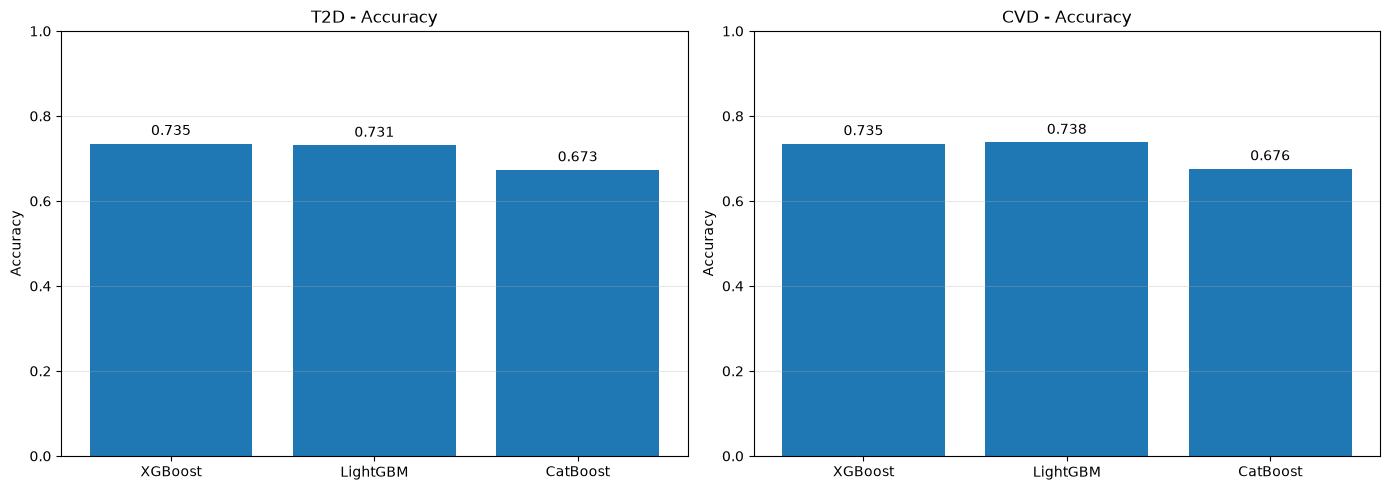

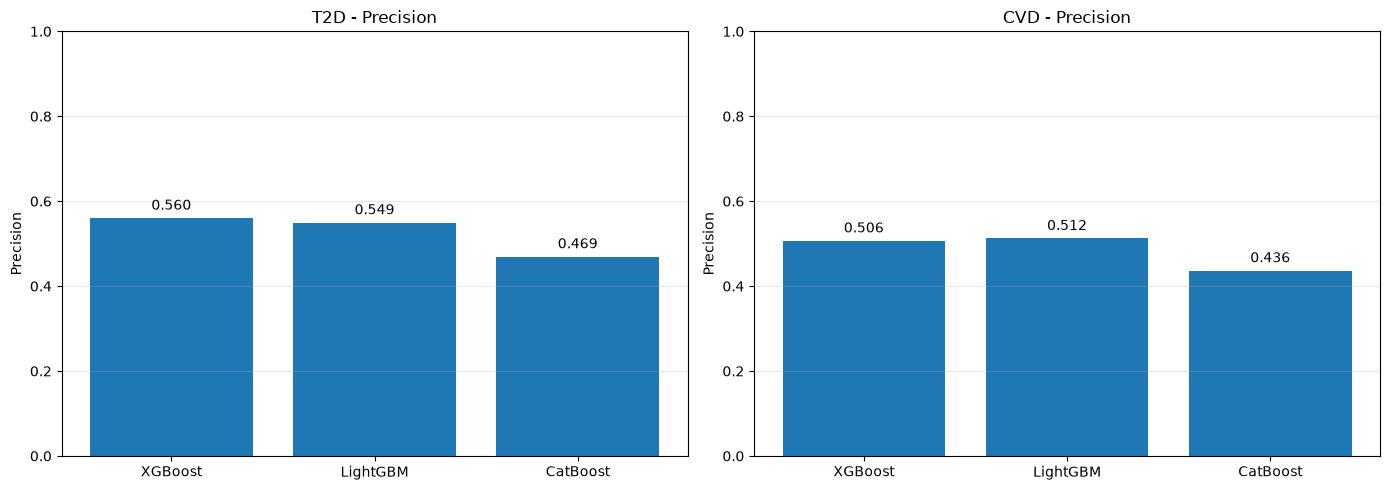

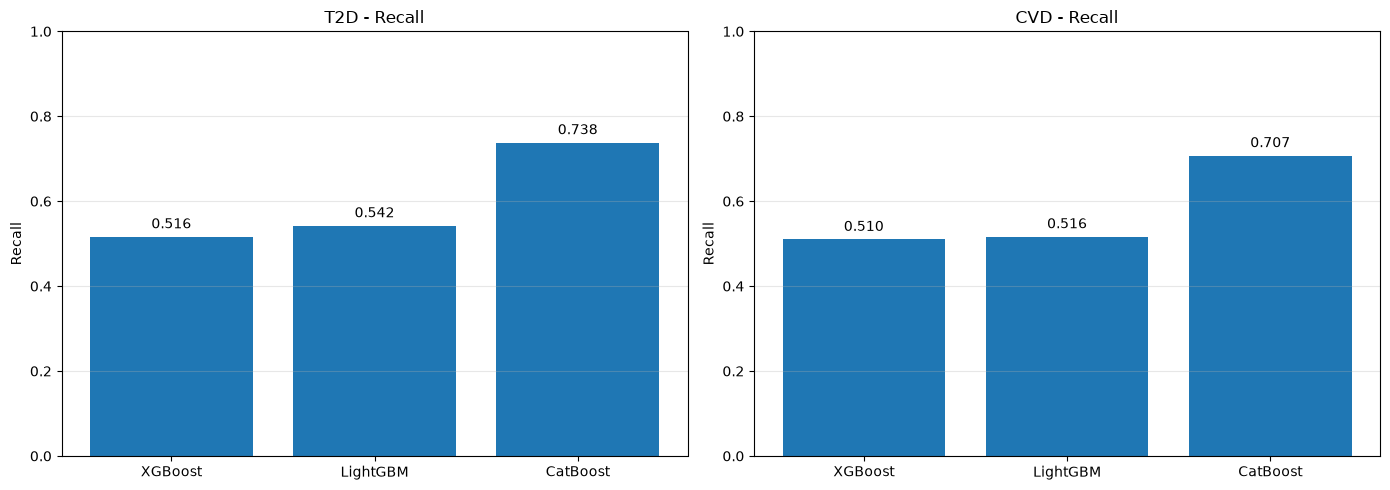

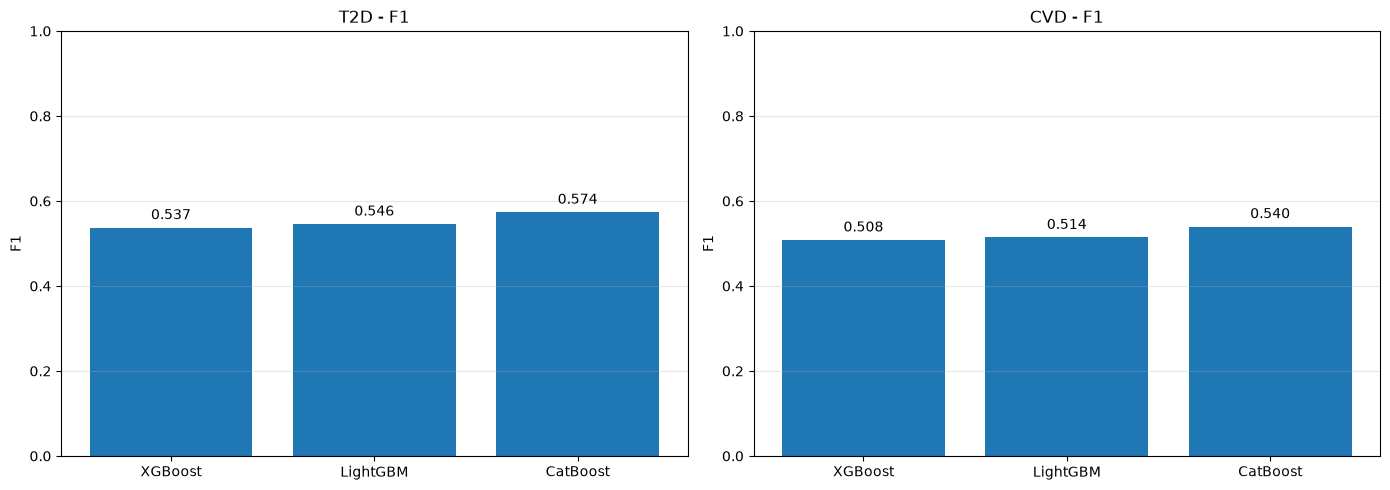

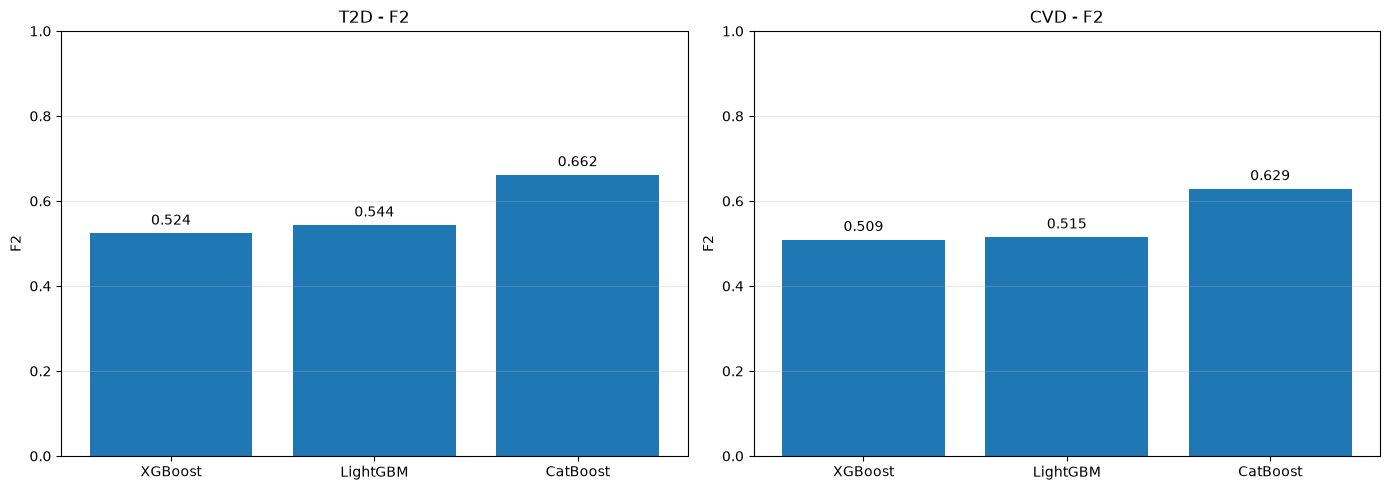

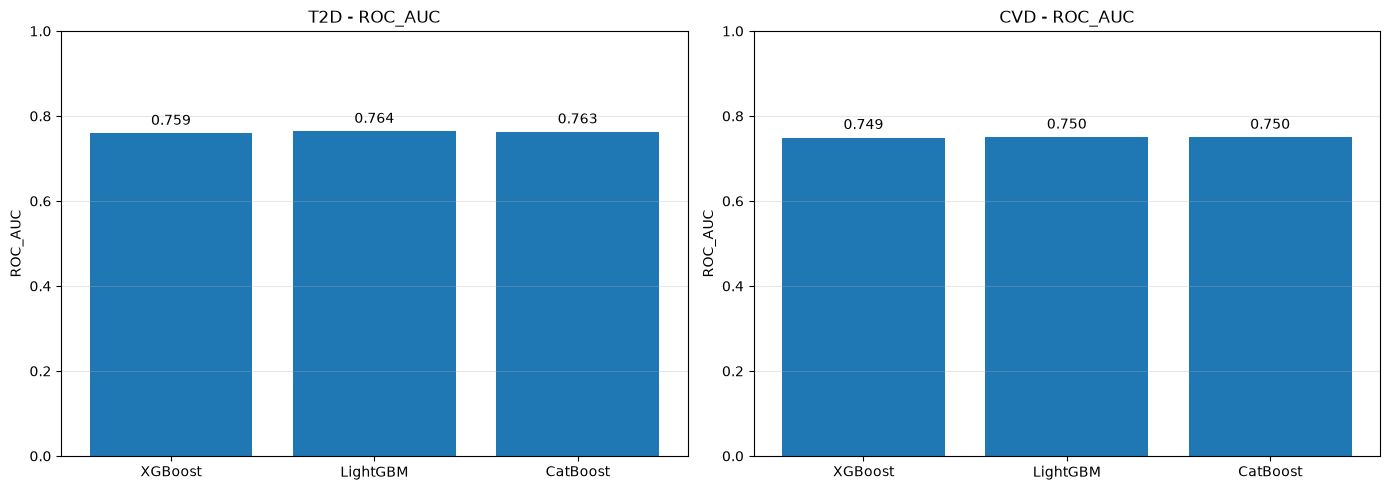

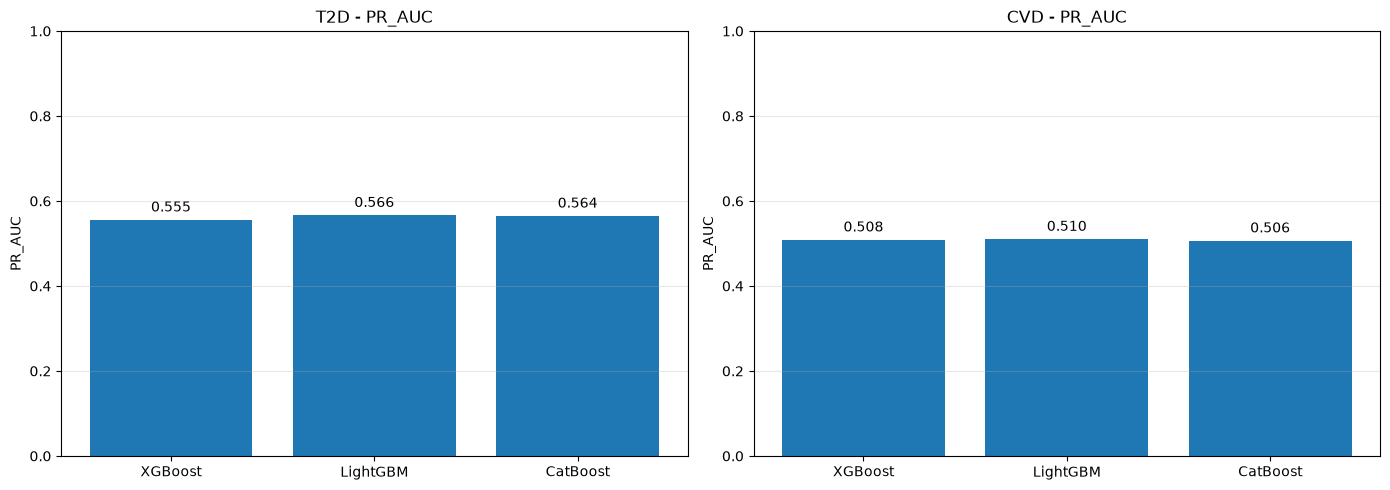

In [ ]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "F2",
    "ROC_AUC",
    "PR_AUC"
]
test = results[results["Dataset"] == "Test"]

for metric in metrics:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for ax, disease in zip(axes, ["T2D", "CVD"]):
        data = test[test["Model"].notna()].copy()

        data = results[
            (results["Dataset"] == "Test") &
            (
                results.index.isin(
                    results.index
                )
            )
        ]

        if disease == "T2D":
            data = pd.DataFrame(t2d_results)
        else:
            data = pd.DataFrame(cvd_results)

        data = data[data["Dataset"] == "Test"]

        ax.bar(data["Model"], data[metric])
        ax.set_title(f"{disease} - {metric}")
        ax.set_ylabel(metric)
        ax.set_ylim(0, 1)
        ax.grid(axis="y", alpha=0.3)

        for i, v in enumerate(data[metric]):
            ax.text(i, v + 0.02, f"{v:.3f}", ha="center")

    plt.tight_layout()
    plt.show()

In [ ]:
def plot_confusion(models, X_test, y_test, disease, threshold=0.5):

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for ax, (name, model) in zip(axes, models.items()):
        prob = model.predict_proba(X_test)[:, 1]
        pred = (prob >= threshold).astype(int)

        ConfusionMatrixDisplay.from_predictions(
            y_test,
            pred,
            display_labels=["Không bệnh", "Có bệnh"],
            cmap="Blues",
            ax=ax
        )

        ax.set_title(f"{disease} - {name}")

    plt.tight_layout()
    plt.show()

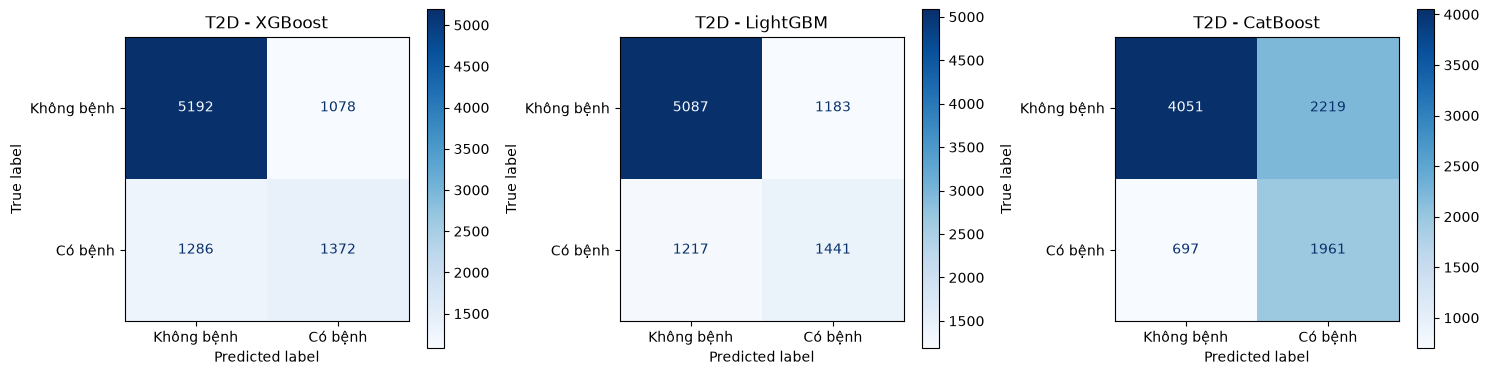

In [ ]:
plot_confusion(
    t2d_models,
    X_t2d_test,
    y_t2d_test,
    "T2D"
)

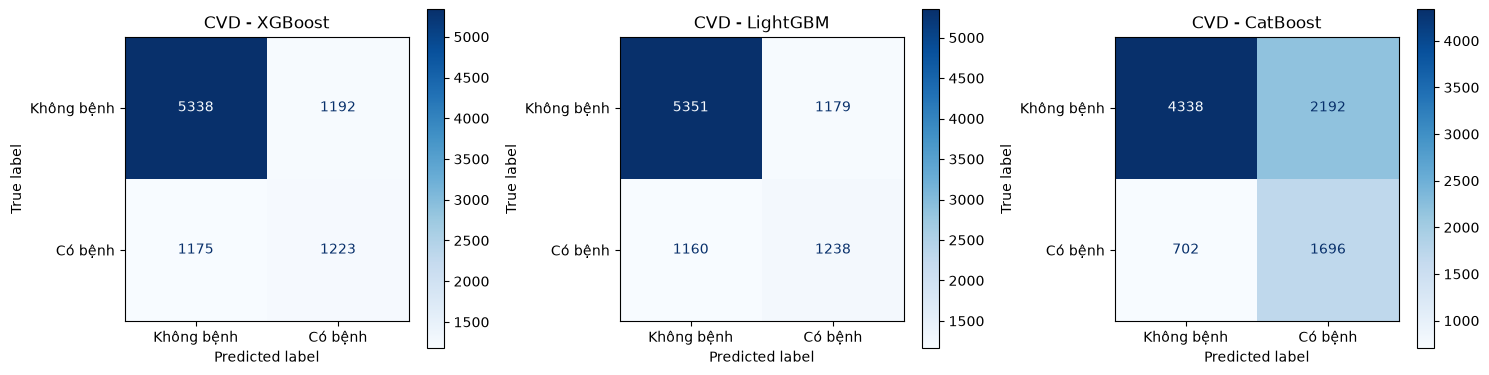

In [ ]:
plot_confusion(
    cvd_models,
    X_cvd_test,
    y_cvd_test,
    "CVD"
)

In [ ]:
# model = joblib.load(
#     MODEL_DIR / "t2d_xgboost.pkl"
# )

# prob = model.predict_proba(X_t2d_test)[:, 1]
# pred = (prob >= 0.5).astype(int)

### Threshold

In [ ]:
def threshold_tuning(models, X_val, y_val, disease):
    rows = []

    for name, model in models.items():
        prob = model.predict_proba(X_val)[:, 1]
        pr_auc = average_precision_score(y_val, prob)

        for threshold in np.arange(0.10, 0.51, 0.05):
            pred = (prob >= threshold).astype(int)

            rows.append({
                "Disease": disease,
                "Model": name,
                "Threshold": round(threshold, 2),
                "Precision": precision_score(
                    y_val, pred, zero_division=0
                ),
                "Recall": recall_score(
                    y_val, pred, zero_division=0
                ),
                "F1": f1_score(
                    y_val, pred, zero_division=0
                ),
                "F2": fbeta_score(
                    y_val, pred, beta=2, zero_division=0
                ),
                "PR_AUC": pr_auc
            })

    return pd.DataFrame(rows)

In [ ]:
t2d_threshold = threshold_tuning(
    t2d_models, X_t2d_val, y_t2d_val, "T2D"
)

cvd_threshold = threshold_tuning(
    cvd_models, X_cvd_val, y_cvd_val, "CVD"
)

display(t2d_threshold)
display(cvd_threshold)

,Disease,Model,Threshold,Precision,Recall,F1,F2,PR_AUC
0,T2D,XGBoost,0.10,0.295374,0.998506,0.455889,0.676451,0.533133
1,T2D,XGBoost,0.15,0.321283,0.982570,0.484231,0.696042,0.533133
2,T2D,XGBoost,0.20,0.344754,0.962151,0.507620,0.708419,0.533133
3,T2D,XGBoost,0.25,0.367091,0.933267,0.526923,0.713253,0.533133
4,T2D,XGBoost,0.30,0.386893,0.884960,0.538403,0.703762,0.533133
5,T2D,XGBoost,0.35,0.414952,0.823705,0.551885,0.688134,0.533133
6,T2D,XGBoost,0.40,0.446821,0.749004,0.559732,0.659765,0.533133
7,T2D,XGBoost,0.45,0.477313,0.665339,0.555856,0.616748,0.533133
8,T2D,XGBoost,0.50,0.527738,0.554283,0.540685,0.548762,0.533133
9,T2D,LightGBM,0.10,0.311414,0.990538,0.473853,0.689715,0.530661


,Disease,Model,Threshold,Precision,Recall,F1,F2,PR_AUC
0,CVD,XGBoost,0.10,0.304535,0.980463,0.464725,0.679034,0.552569
1,CVD,XGBoost,0.15,0.323711,0.968638,0.485254,0.692647,0.552569
2,CVD,XGBoost,0.20,0.347193,0.944473,0.507739,0.702701,0.552569
3,CVD,XGBoost,0.25,0.372127,0.907455,0.527811,0.704703,0.552569
4,CVD,XGBoost,0.30,0.400672,0.858612,0.546377,0.698862,0.552569
5,CVD,XGBoost,0.35,0.430498,0.804113,0.560774,0.685184,0.552569
6,CVD,XGBoost,0.40,0.468293,0.740360,0.573705,0.663289,0.552569
7,CVD,XGBoost,0.45,0.492561,0.646787,0.559235,0.608670,0.552569
8,CVD,XGBoost,0.50,0.521287,0.541388,0.531148,0.537245,0.552569
9,CVD,LightGBM,0.10,0.307966,0.979949,0.468650,0.682225,0.554678


In [ ]:
import shap
shap.initjs()

def shap_analysis(models, X_test, disease, max_display=20):
    for name, model in models.items():
        print(f"{disease} — {name}")

        explainer   = shap.TreeExplainer(model)
        shap_values = explainer(X_test)

        # Bar plot: feature importance tổng hợp
        fig, ax = plt.subplots(figsize=(10, 6))
        shap.plots.bar(shap_values, max_display=max_display, show=False)
        plt.title(f"{disease} — {name} | Mean |SHAP|", fontsize=13)
        plt.tight_layout()
        plt.show()

        # Beeswarm: phân phối SHAP theo feature
        fig, ax = plt.subplots(figsize=(10, 8))
        shap.plots.beeswarm(shap_values, max_display=max_display, show=False)
        plt.title(f"{disease} — {name} | SHAP Beeswarm", fontsize=13)
        plt.tight_layout()
        plt.show()

T2D — XGBoost


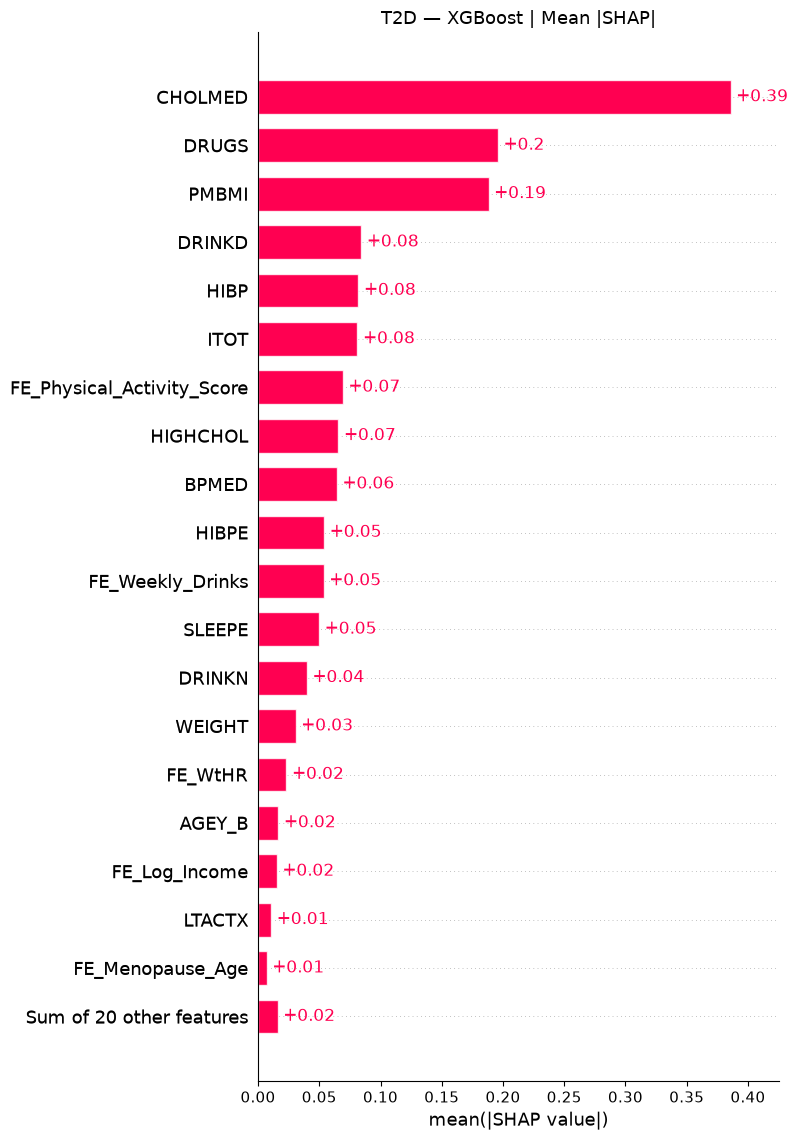

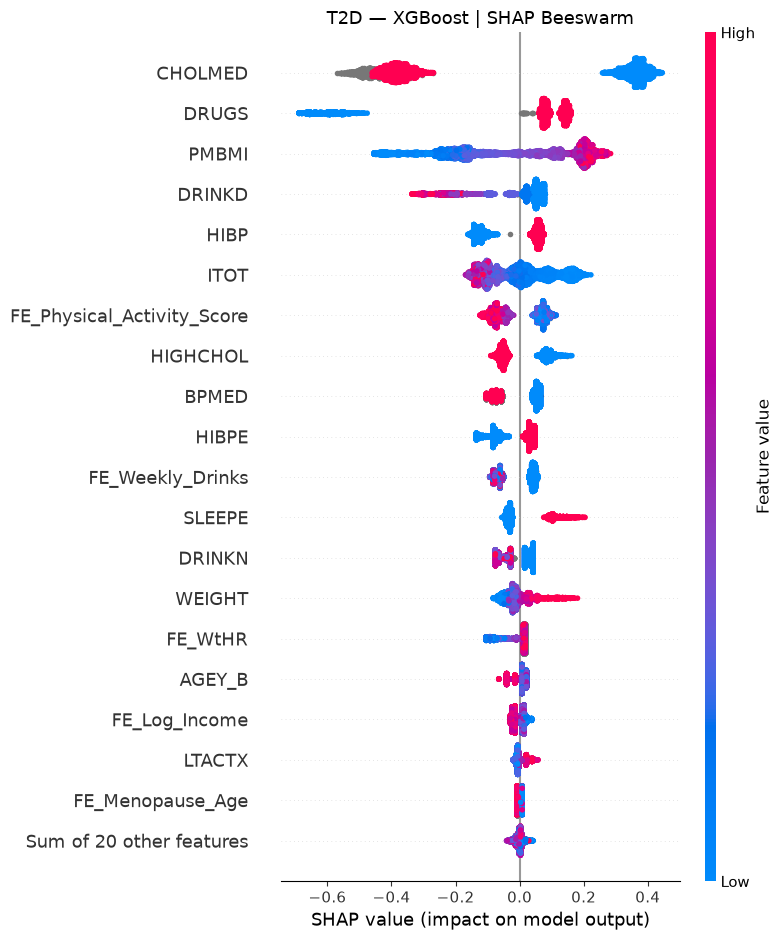

T2D — LightGBM


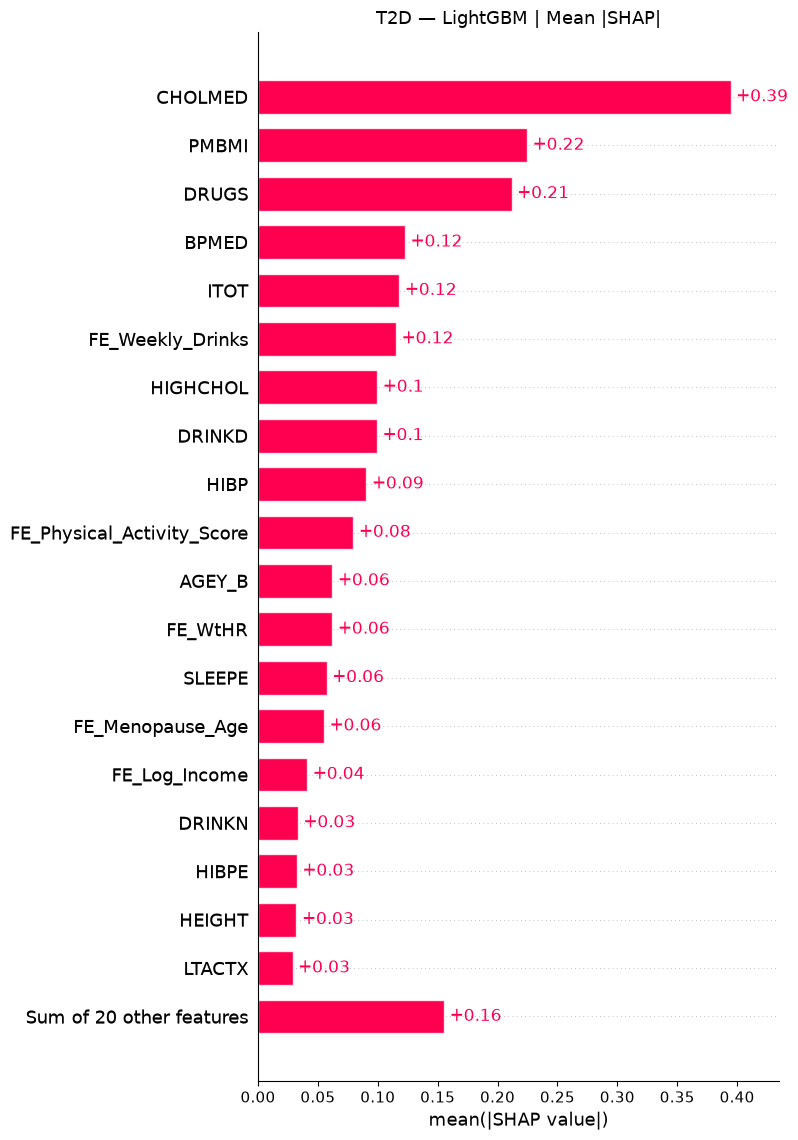

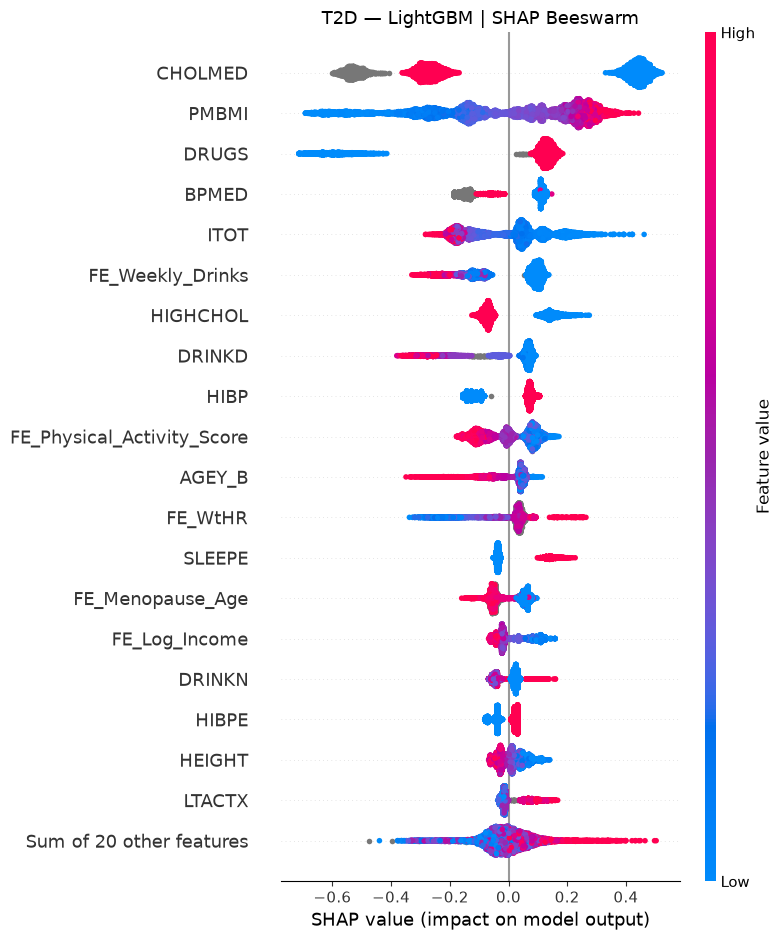

T2D — CatBoost


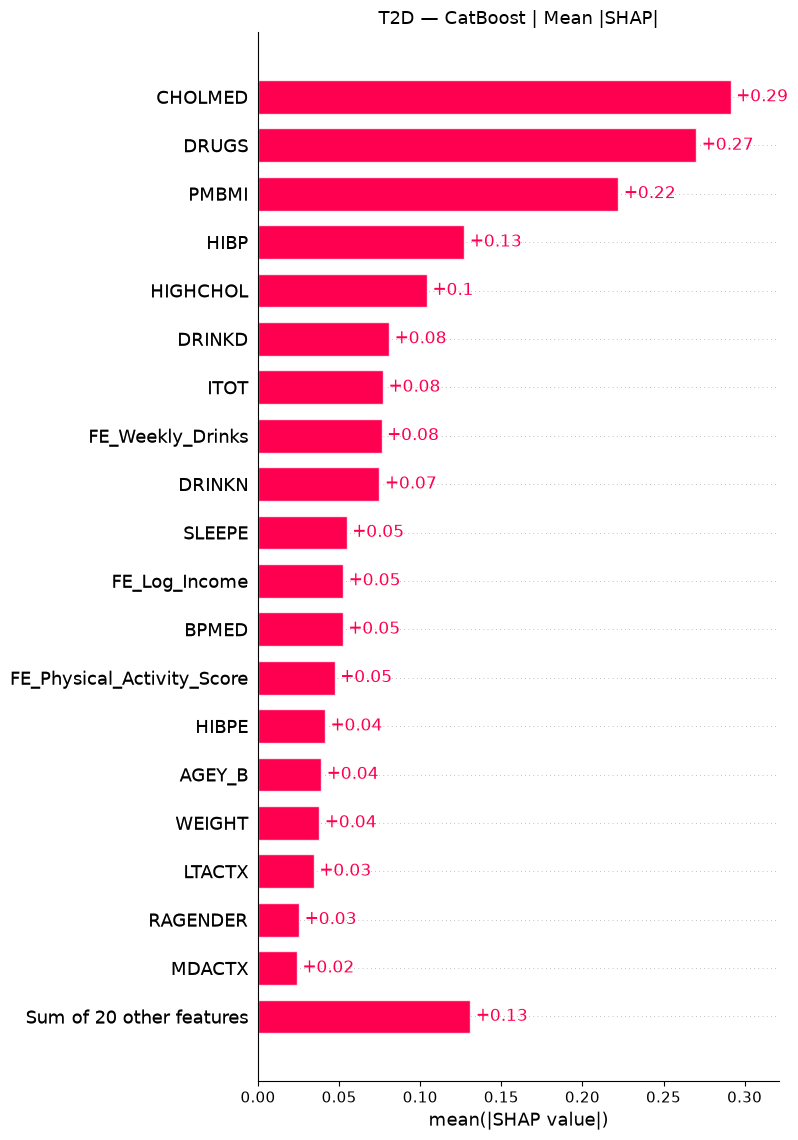

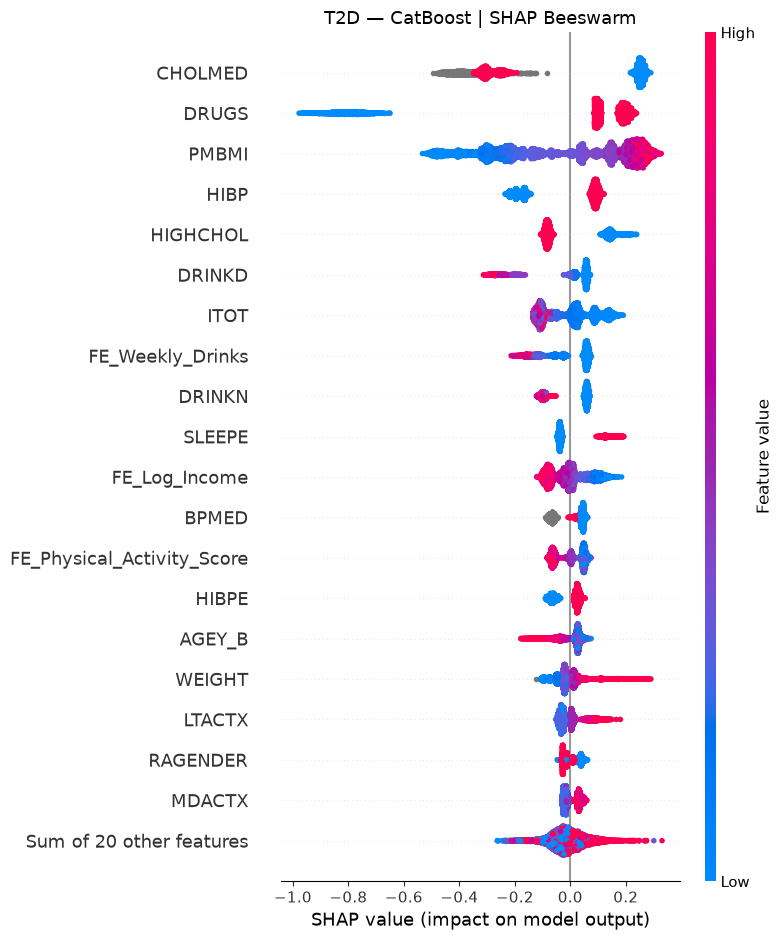

CVD — XGBoost


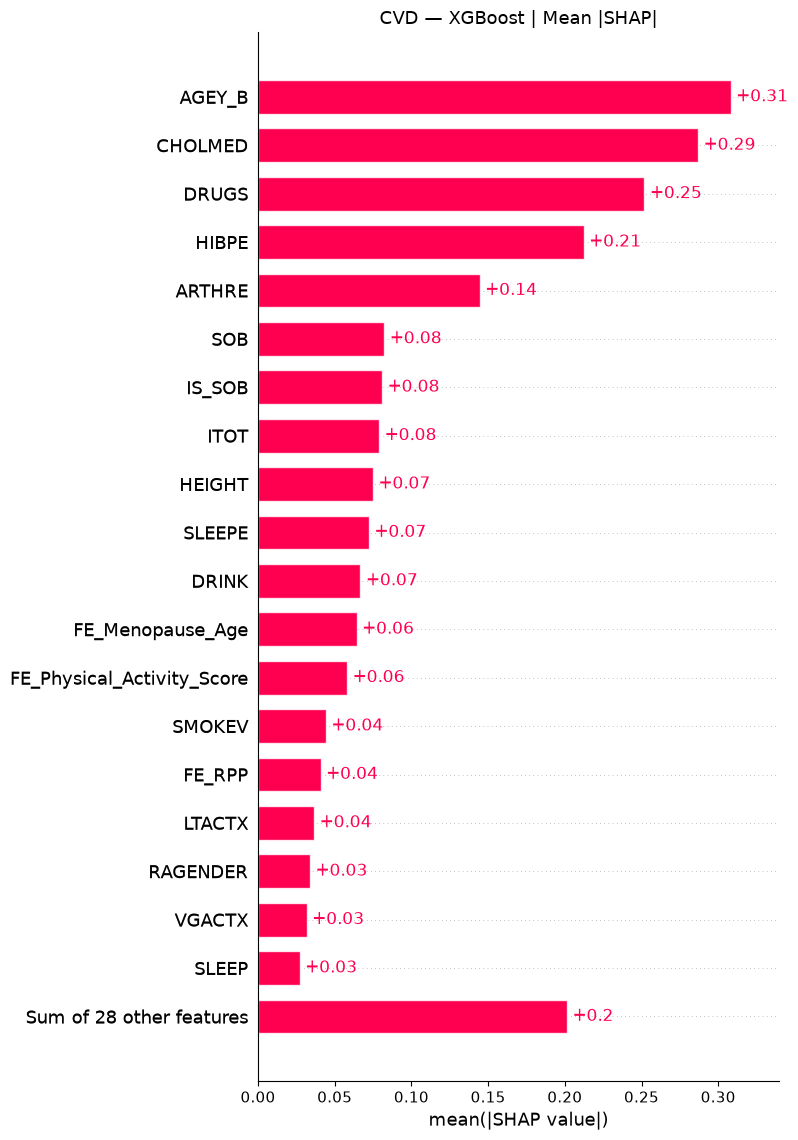

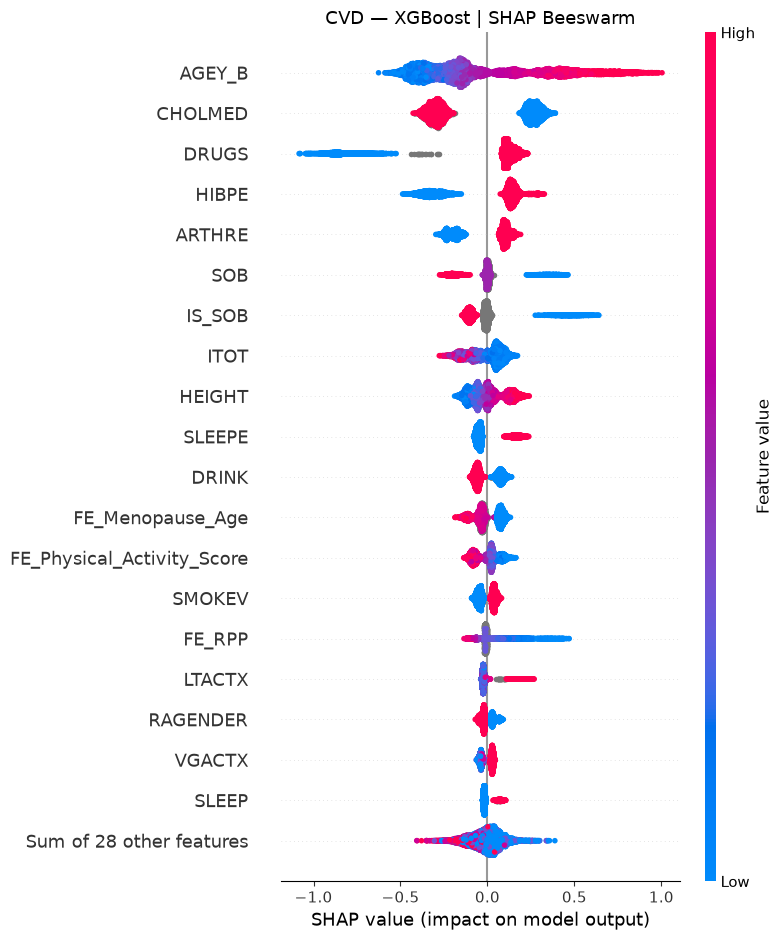

CVD — LightGBM


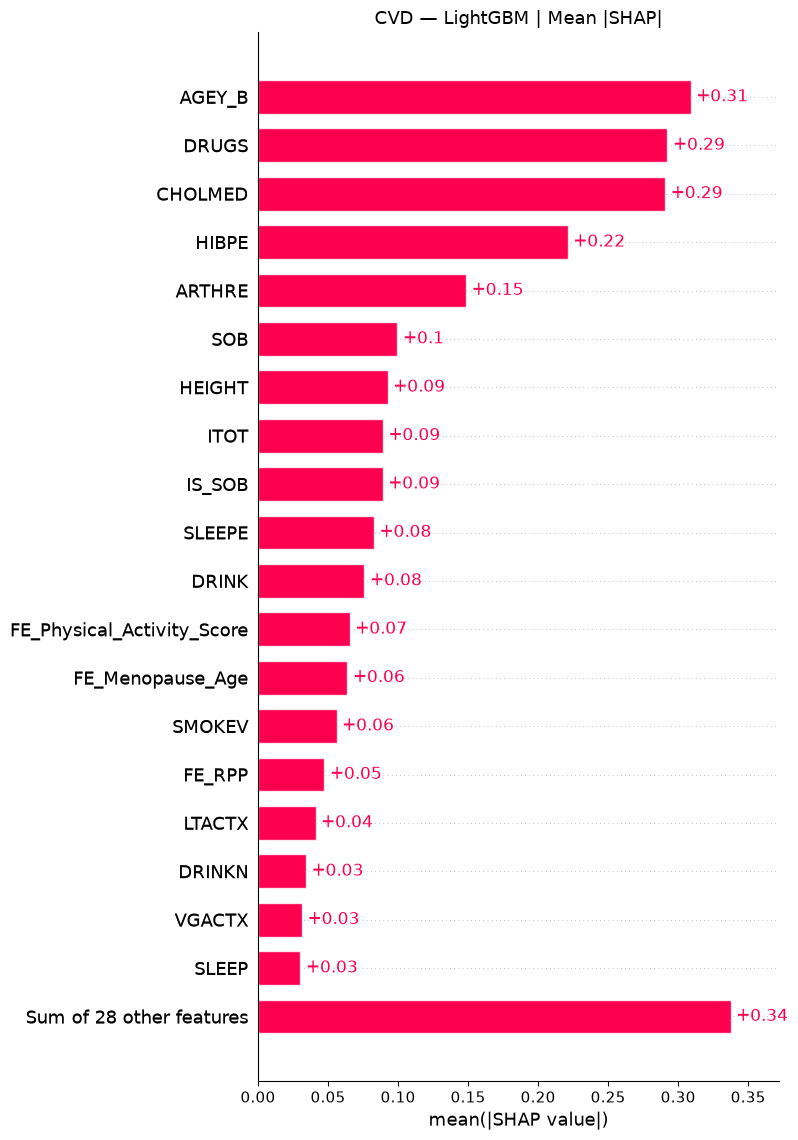

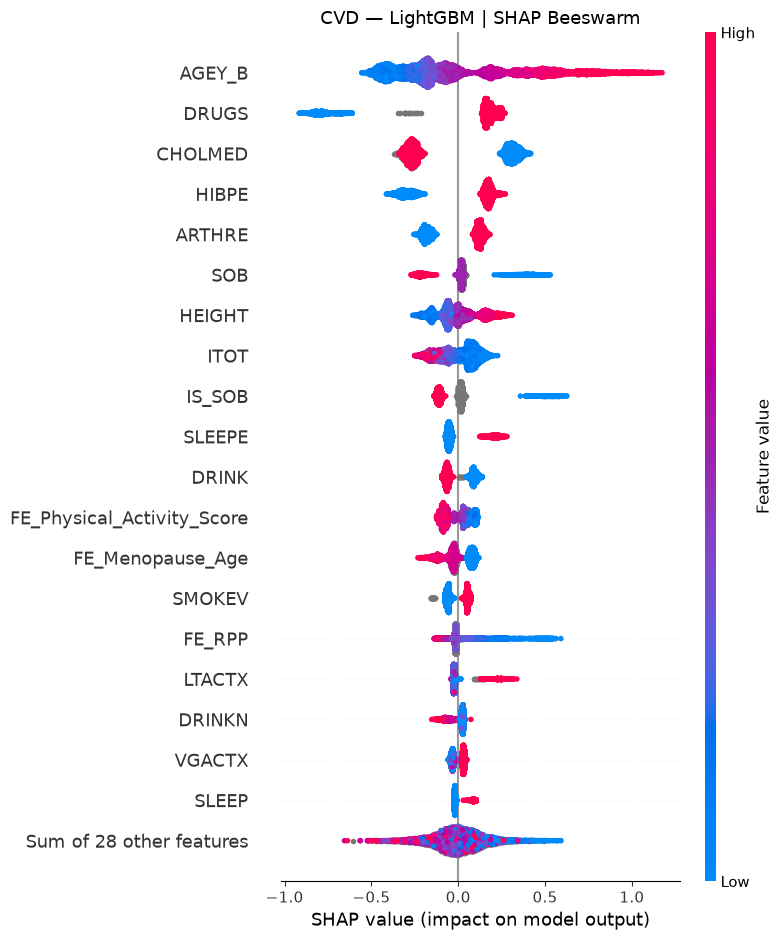

CVD — CatBoost


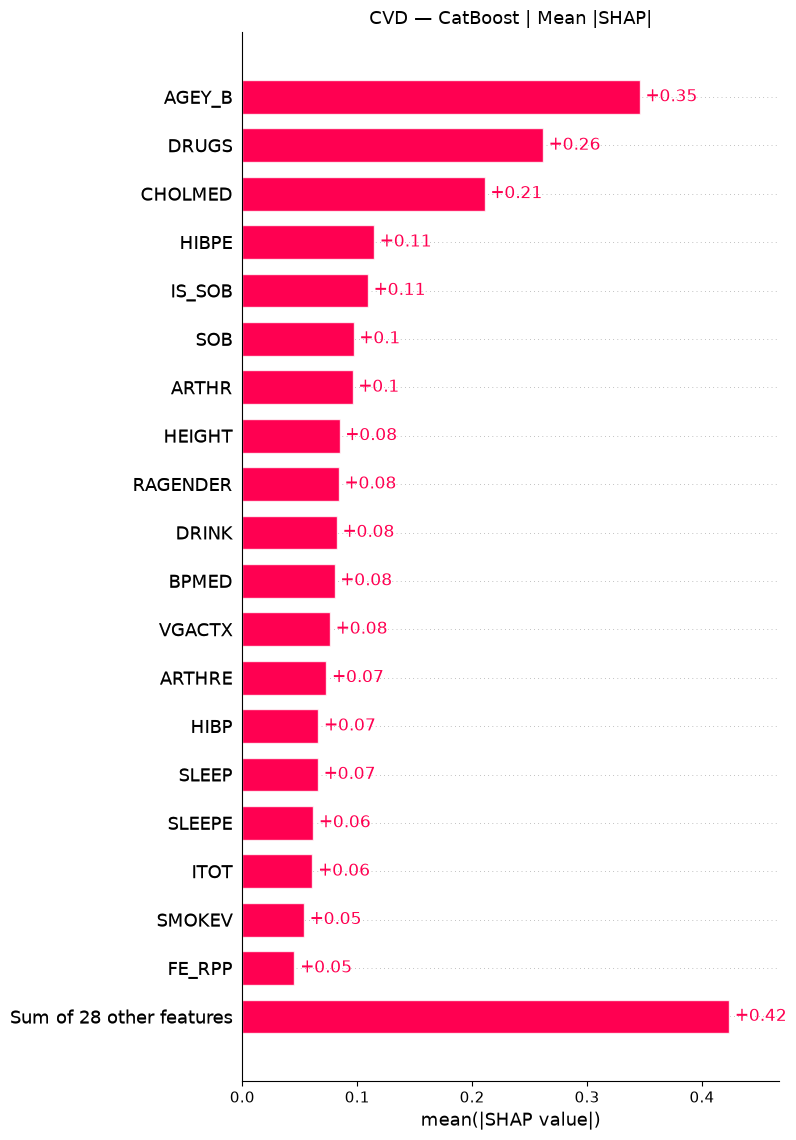

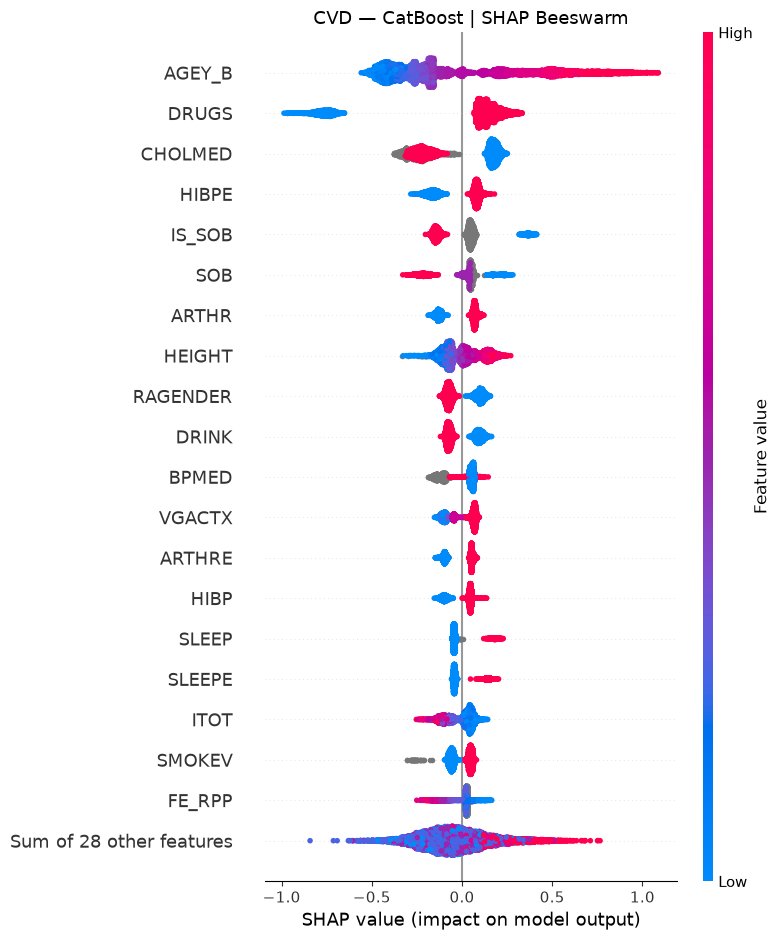

In [ ]:
shap_analysis(t2d_models, X_t2d_test, "T2D")
shap_analysis(cvd_models, X_cvd_test, "CVD")

In [ ]:
def shap_top_features(models, X_test, disease, top_n=15):
    """Bảng top feature theo mean |SHAP| của từng model."""
    dfs = []
    for name, model in models.items():
        explainer   = shap.TreeExplainer(model)
        sv          = explainer(X_test)
        importance  = pd.Series(
            np.abs(sv.values).mean(axis=0),
            index=X_test.columns,
            name=name
        )
        dfs.append(importance)

    result = pd.concat(dfs, axis=1).sort_values(
        by=list(models.keys())[0], ascending=False
    ).head(top_n)

    print(f"\n=== Top {top_n} Features — {disease} ===")
    display(result.style.format("{:.4f}").background_gradient(cmap="YlOrRd"))

# Chạy:
shap_top_features(t2d_models, X_t2d_test, "T2D")
shap_top_features(cvd_models, X_cvd_test, "CVD")



=== Top 15 Features — T2D ===


,XGBoost,LightGBM,CatBoost
CHOLMED,0.3858,0.3945,0.2913
DRUGS,0.1959,0.2117,0.2701
PMBMI,0.1882,0.2246,0.2221
DRINKD,0.0843,0.0993,0.0808
HIBP,0.0820,0.0904,0.1272
ITOT,0.0812,0.1179,0.0770
FE_Physical_Activity_Score,0.0692,0.0796,0.0473
HIGHCHOL,0.0656,0.0995,0.1041
BPMED,0.0644,0.1227,0.0522
HIBPE,0.0540,0.0324,0.0412



=== Top 15 Features — CVD ===


,XGBoost,LightGBM,CatBoost
AGEY_B,0.3081,0.3089,0.3458
CHOLMED,0.2868,0.2907,0.2109
DRUGS,0.2518,0.2923,0.2616
HIBPE,0.2122,0.2211,0.1146
ARTHRE,0.1444,0.1486,0.0731
SOB,0.0823,0.0996,0.0968
IS_SOB,0.0809,0.0890,0.1093
ITOT,0.0789,0.0891,0.0610
HEIGHT,0.0749,0.0926,0.0846
SLEEPE,0.0722,0.0828,0.0616
